# Predicción de abandono de clientes (Customer Churn) con XGBoost

**Asignatura:** Inteligencia Artificial I — Proyecto final
**Algoritmo:** Gradient Boosting con `XGBClassifier` (entrenado desde cero)
**Dataset:** Telco Customer Churn (IBM) — 7,043 clientes, 21 columnas

Contenido:
1. Carga y exploración inicial
2. Análisis exploratorio (EDA)
3. Preprocesamiento
4. Entrenamiento y ajuste de hiperparámetros
5. Evaluación
6. Serialización del pipeline

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Raíz del proyecto (funciona ejecutando desde notebooks/ o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.preprocessing import (
    CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET, cargar_datos,
    construir_preprocesador, guardar_datos_procesados, limpiar_datos,
    separar_features_objetivo,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\proyectos\proyecto-xgboost-grupo7


## 1. Carga y exploración inicial

In [2]:
df_raw = cargar_datos(ROOT / "data" / "raw" / "telco_churn.csv")
print("Dimensiones:", df_raw.shape)
df_raw.head()

Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
balance = df_raw["Churn"].value_counts()
print(balance)
print((balance / len(df_raw) * 100).round(2).astype(str) + " %")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46 %
Yes    26.54 %
Name: count, dtype: str


El dataset está **desbalanceado** (≈73 % No / 27 % Yes). Por eso usamos una división
estratificada y evaluamos además de accuracy métricas como Recall, F1 y ROC-AUC.

## 2. Análisis exploratorio (EDA)

### 2.1 Valores nulos

In [6]:
print("Nulos por columna (CSV original):")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
vacios = (df_raw["TotalCharges"].astype(str).str.strip() == "").sum()
print(f"TotalCharges con cadenas vacías: {vacios}")
print(df_raw.loc[df_raw["TotalCharges"].astype(str).str.strip() == "", ["tenure", "MonthlyCharges", "TotalCharges"]])

Nulos por columna (CSV original):
Series([], dtype: int64)
TotalCharges con cadenas vacías: 11
      tenure  MonthlyCharges TotalCharges
488        0           52.55             
753        0           20.25             
936        0           80.85             
1082       0           25.75             
1340       0           56.05             
3331       0           19.85             
3826       0           25.35             
4380       0           20.00             
5218       0           19.70             
6670       0           73.35             
6754       0           61.90             


`TotalCharges` viene como texto y tiene 11 cadenas vacías, todas en clientes con
`tenure = 0` (aún no han sido facturados). Se imputan con **0** durante la limpieza.

In [7]:
df = limpiar_datos(df_raw)
print("Dimensiones tras limpieza:", df.shape)
print("Nulos restantes:", int(df.isna().sum().sum()))
df.head()

Dimensiones tras limpieza: (7043, 20)
Nulos restantes: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### 2.2 Distribución de variables numéricas

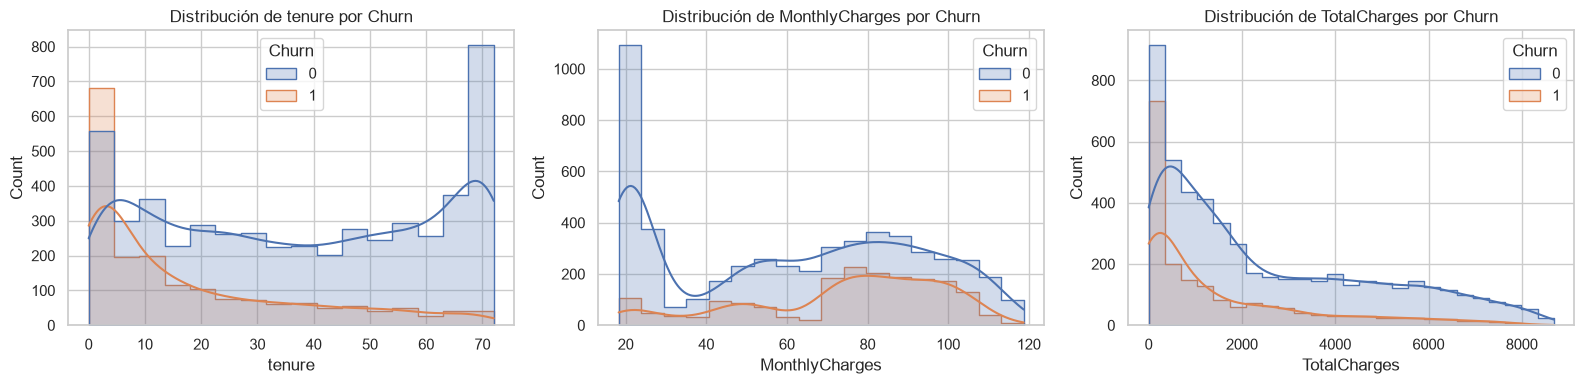

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, ax=ax, element="step")
    ax.set_title(f"Distribución de {col} por Churn")
plt.tight_layout()
plt.show()

### 2.3 Detección de outliers

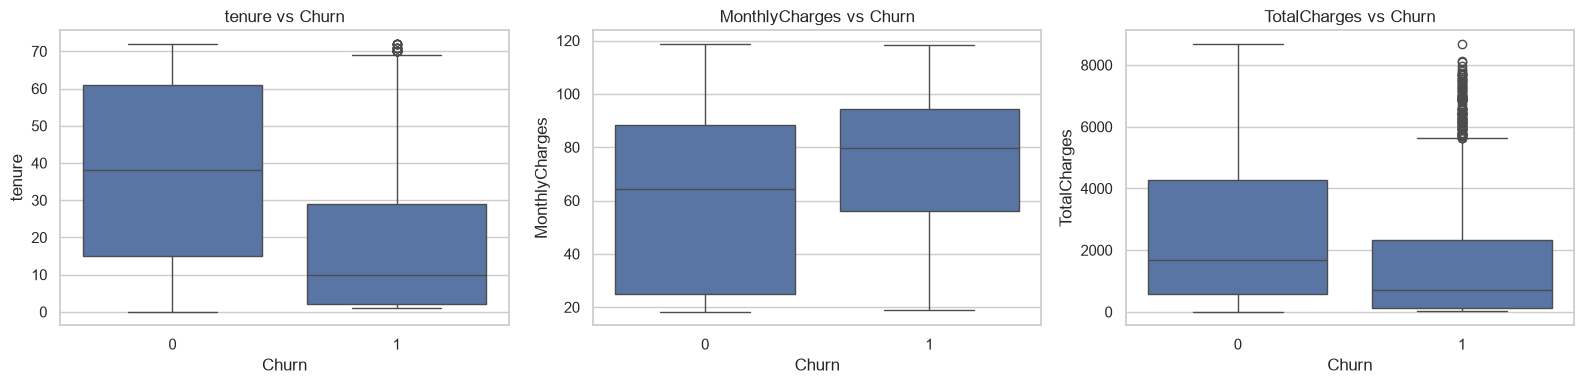

tenure: 0 outliers según la regla IQR
MonthlyCharges: 0 outliers según la regla IQR
TotalCharges: 0 outliers según la regla IQR


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outliers según la regla IQR")

No se detectan outliers según la regla IQR en las variables numéricas, por lo que no se
elimina ningún registro. Además, los modelos basados en árboles (XGBoost) son robustos
a valores extremos.

### 2.4 Variables categóricas clave

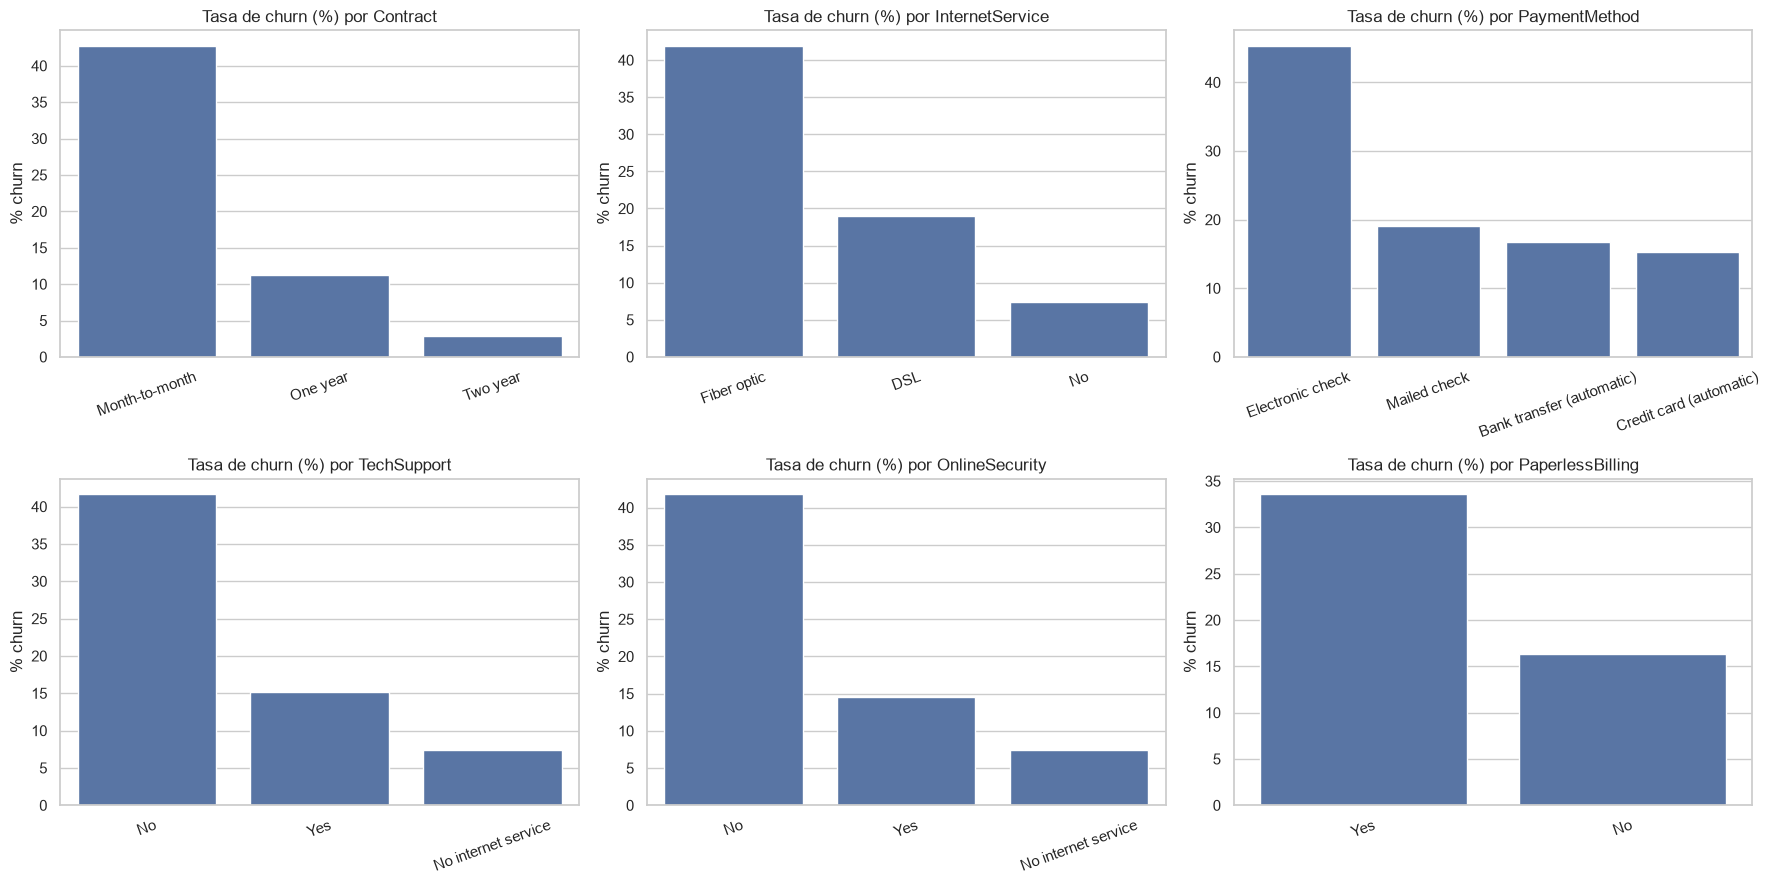

In [10]:
claves = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), claves):
    tasa = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax)
    ax.set_title(f"Tasa de churn (%) por {col}")
    ax.set_ylabel("% churn")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Observaciones: los contratos **mes a mes**, el internet de **fibra óptica**, el pago con
**cheque electrónico** y la ausencia de **soporte técnico / seguridad online** se asocian
con tasas de abandono mucho mayores.

### 2.5 Correlación

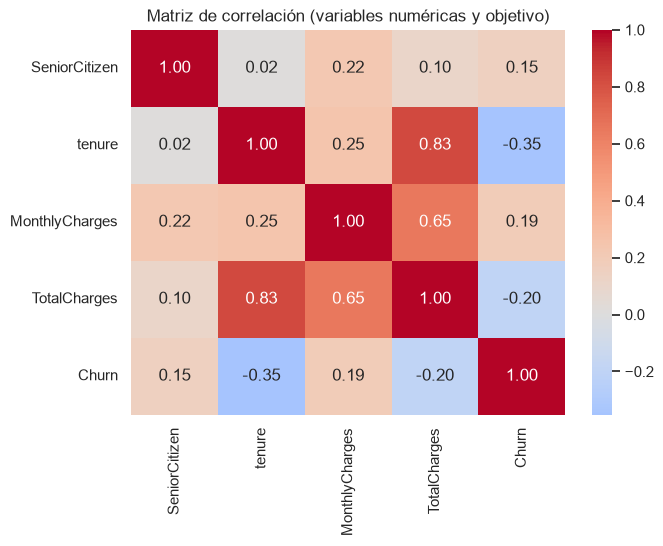

In [11]:
corr = df[NUMERIC_FEATURES + [TARGET]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (variables numéricas y objetivo)")
plt.show()

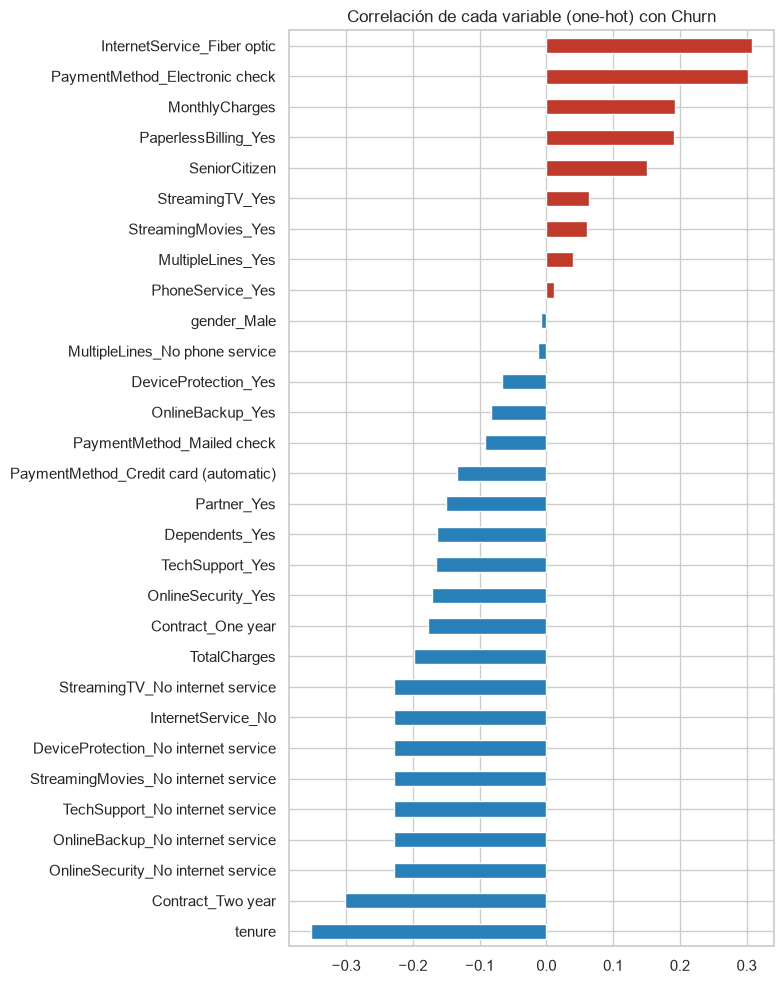

In [12]:
corr_full = pd.get_dummies(df, drop_first=True, dtype=float).corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(8, 10))
corr_full.plot(kind="barh", color=np.where(corr_full > 0, "#c0392b", "#2980b9"))
plt.title("Correlación de cada variable (one-hot) con Churn")
plt.tight_layout()
plt.show()

## 3. Preprocesamiento

- Limpieza (`src.preprocessing.limpiar_datos`): eliminación de `customerID`, conversión de
  `TotalCharges` a numérico, imputación de vacíos y codificación de `Churn` a 0/1.
- Transformación (`src.preprocessing.construir_preprocesador`): `ColumnTransformer` con
  imputación + `StandardScaler` para numéricas e imputación + `OneHotEncoder` para categóricas.
- División estratificada 80/20 con `random_state=42`.

El preprocesador forma parte del mismo `Pipeline` que el modelo, de modo que la
aplicación aplica **exactamente** las mismas transformaciones.

In [13]:
ruta_proc = guardar_datos_procesados(df, ROOT / "data" / "processed" / "telco_churn_clean.csv")
print("Dataset limpio guardado en:", ruta_proc.relative_to(ROOT))

X, y = separar_features_objetivo(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Proporción churn train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

# Guardar también las particiones para trazabilidad
X_train.assign(**{TARGET: y_train}).to_csv(ROOT / "data" / "processed" / "train.csv", index=False)
X_test.assign(**{TARGET: y_test}).to_csv(ROOT / "data" / "processed" / "test.csv", index=False)

preprocesador = construir_preprocesador()
print("Features tras transformación:", preprocesador.fit(X_train).transform(X_train).shape[1])

Dataset limpio guardado en: data\processed\telco_churn_clean.csv
Train: (5634, 19)  Test: (1409, 19)
Proporción churn train/test: 0.2654 0.2654
Features tras transformación: 45


## 4. Entrenamiento del modelo

Se entrena un `XGBClassifier` dentro de un `Pipeline` y se ajustan sus hiperparámetros con
`RandomizedSearchCV` (40 combinaciones, validación cruzada estratificada de 5 folds,
métrica ROC-AUC).

In [14]:
pipeline = Pipeline(steps=[
    ("preprocessor", construir_preprocesador()),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 600],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5, 7],
    "model__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.5, 0.6, 0.7, 0.8, 1.0],
    "model__gamma": [0, 0.1, 0.5, 1],
    "model__reg_lambda": [0.5, 1, 2, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    pipeline, param_distributions, n_iter=40, scoring="roc_auc", cv=cv,
    n_jobs=-1, random_state=RANDOM_STATE, refit=True,
)
search.fit(X_train, y_train)

print(f"Mejor ROC-AUC en validación cruzada: {search.best_score_:.4f}")
print("Mejores hiperparámetros:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__', '')}: {v}")
best_model = search.best_estimator_

Mejor ROC-AUC en validación cruzada: 0.8506
Mejores hiperparámetros:
  subsample: 0.8
  reg_lambda: 1
  n_estimators: 300
  min_child_weight: 7
  max_depth: 3
  learning_rate: 0.02
  gamma: 0
  colsample_bytree: 0.5


In [15]:
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_results[["rank_test_score", "mean_test_score", "std_test_score"]].head(10)

,rank_test_score,mean_test_score,std_test_score
34,1,0.850635,0.011640
14,2,0.850081,0.011787
31,3,0.849965,0.011281
10,4,0.849915,0.011214
20,5,0.849902,0.011882
23,6,0.849773,0.010335
18,7,0.849705,0.011408
15,8,0.849676,0.010879
26,9,0.849658,0.011324
29,10,0.849564,0.011069


## 5. Evaluación en el conjunto de prueba

In [16]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}
tabla_metricas = pd.DataFrame(metricas, index=["XGBoost (test)"]).T.round(4)
display(tabla_metricas)
assert metricas["Accuracy"] > 0.70, "El accuracy no supera el mínimo del 70 %"
print(f"Accuracy = {metricas['Accuracy']:.2%} (> 70 % requerido)")

,XGBoost (test)
Accuracy,0.8084
Precision,0.6806
Recall,0.5241
F1-Score,0.5921
ROC-AUC,0.8488


Accuracy = 80.84% (> 70 % requerido)


In [17]:
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.68      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



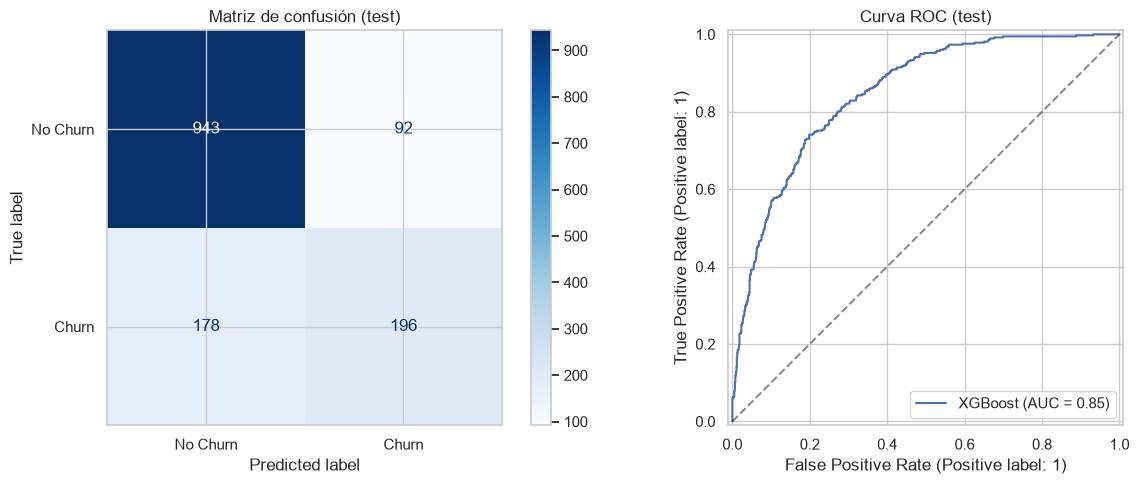

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred), display_labels=["No Churn", "Churn"]
).plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de confusión (test)")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name="XGBoost")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("Curva ROC (test)")
plt.tight_layout()
plt.show()

### 5.1 Importancia de características

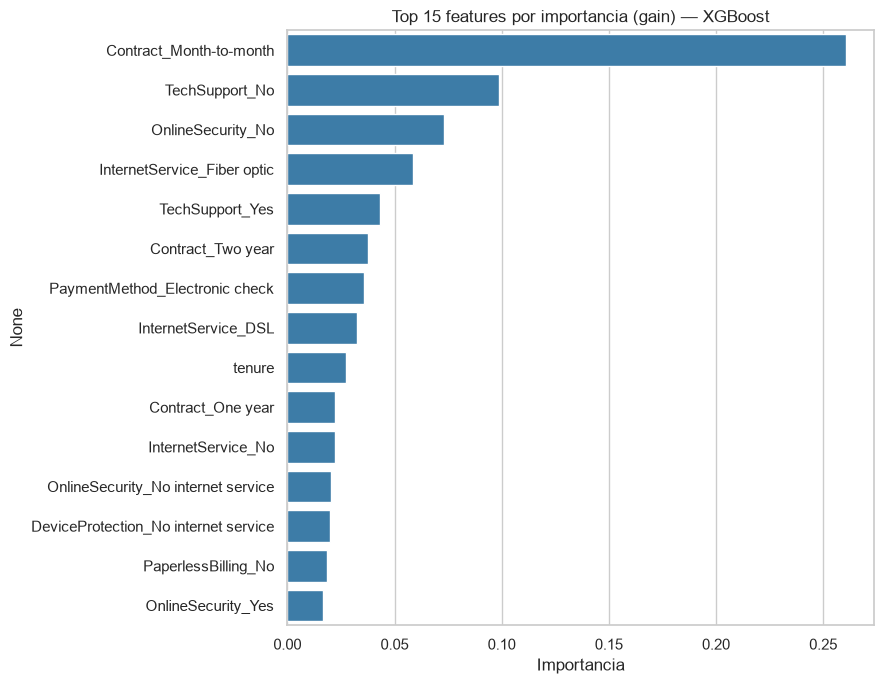

Contract_Month-to-month                 0.2607
TechSupport_No                          0.0986
OnlineSecurity_No                       0.0730
InternetService_Fiber optic             0.0584
TechSupport_Yes                         0.0432
Contract_Two year                       0.0375
PaymentMethod_Electronic check          0.0357
InternetService_DSL                     0.0326
tenure                                  0.0275
Contract_One year                       0.0223
InternetService_No                      0.0220
OnlineSecurity_No internet service      0.0203
DeviceProtection_No internet service    0.0198
PaperlessBilling_No                     0.0187
OnlineSecurity_Yes                      0.0164
dtype: float32

In [19]:
nombres = best_model.named_steps["preprocessor"].get_feature_names_out()
nombres = [n.split("__", 1)[1] for n in nombres]
importancias = pd.Series(
    best_model.named_steps["model"].feature_importances_, index=nombres
).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=importancias.head(15).values, y=importancias.head(15).index, color="#2c7fb8")
plt.title("Top 15 features por importancia (gain) — XGBoost")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()
importancias.head(15).round(4)

El tipo de contrato, el servicio de internet de fibra óptica, el soporte técnico, la
seguridad online y la antigüedad (`tenure`) son los factores más determinantes, lo cual
coincide con lo observado en el EDA.

## 6. Serialización del pipeline completo

In [20]:
model_path = ROOT / "models" / "modelo.pkl"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, model_path)
size_mb = model_path.stat().st_size / 1024 ** 2
print(f"Modelo guardado en {model_path.relative_to(ROOT)} ({size_mb:.3f} MB)")
assert size_mb < 100, "El modelo supera el límite de 100 MB de GitHub"

# Verificación: recargar y comparar predicciones
modelo_cargado = joblib.load(model_path)
assert np.allclose(modelo_cargado.predict_proba(X_test)[:, 1], y_proba)
print("Verificación de recarga: OK")

Modelo guardado en models\modelo.pkl (0.344 MB)
Verificación de recarga: OK


## Conclusiones

- El pipeline **preprocesamiento + XGBoost** supera ampliamente el mínimo de 70 % de
  accuracy y obtiene un ROC-AUC alto, lo que indica buena capacidad para ordenar a los
  clientes por riesgo de abandono.
- El recall de la clase *Churn* es moderado debido al desbalance; en un escenario de
  negocio puede reducirse el umbral de decisión para priorizar la detección de clientes en
  riesgo a costa de más falsos positivos.
- El modelo serializado (`models/modelo.pkl`) es consumido por la aplicación Streamlit
  mediante `src/predict.py`.